## Part I: Data Pre-processing

In [2]:
import os
print(f"當前分配到的CPU核心數: {os.cpu_count()}")

當前分配到的CPU核心數: 8


In [4]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 44.4 MB/s eta 0:00:00


In [10]:
import pandas as pd

In [11]:
# Download the Google Analogy dataset
!wget http://download.tensorflow.org/data/questions-words.txt

--2026-10-10 04:59:50--  http://download.tensorflow.org/data/questions-words.txt
Resolving download.tensorflow.org (download.tensorflow.org)... 74.125.23.207, 74.125.203.207, 74.125.204.207, ...
Connecting to download.tensorflow.org (download.tensorflow.org)|74.125.23.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 603955 (590K) [text/plain]
Saving to: ‘questions-words.txt’

questions-words.txt 100%[===================>] 589.80K   741KB/s    in 0.8s    

2026-10-10 04:59:51 (741 KB/s) - ‘questions-words.txt’ saved [603955/603955]



In [12]:
# Preprocess the dataset
file_name = "questions-words"
with open(f"{file_name}.txt", "r") as f:
    data = f.read().splitlines()

In [13]:
# check data from the first 10 entries
for entry in data[:10]:

    print(entry)

: capital-common-countries
Athens Greece Baghdad Iraq
Athens Greece Bangkok Thailand
Athens Greece Beijing China
Athens Greece Berlin Germany
Athens Greece Bern Switzerland
Athens Greece Cairo Egypt
Athens Greece Canberra Australia
Athens Greece Hanoi Vietnam
Athens Greece Havana Cuba


In [14]:
# TODO1: Write your code here for processing data to pd.DataFrame
# Please note that the first five mentions of ": " indicate `semantic`,
# and the remaining nine belong to the `syntatic` category.

categories = [] #父類別
sub_categories = [] #子類別
questions = []

now_category = ""
now_sub_category = ""
category_count = 0
for line in data:
    line = line.strip()
    if not line:
        continue
    if line.startswith(":"):
        category_count += 1
        now_sub_category = line
        if category_count <= 5:
            now_category = "Semantic"
        else:
            now_category = "Syntactic"
    else:
        categories.append(now_category)
        sub_categories.append(now_sub_category)
        questions.append(line)




In [15]:
# Create the dataframe
df = pd.DataFrame(
    {
        "Question": questions,
        "Category": categories,
        "SubCategory": sub_categories,
    }
)

In [16]:
df.head()

,Question,Category,SubCategory
0,Athens Greece Baghdad Iraq,Semantic,: capital-common-countries
1,Athens Greece Bangkok Thailand,Semantic,: capital-common-countries
2,Athens Greece Beijing China,Semantic,: capital-common-countries
3,Athens Greece Berlin Germany,Semantic,: capital-common-countries
4,Athens Greece Bern Switzerland,Semantic,: capital-common-countries


In [10]:
df.to_csv(f"{file_name}.csv", index=False)















































sdsodkokoskdosdko## Part II: Use pre-trained word embeddings
- After finish Part I, you can run Part II code blocks only.

In [17]:
import pandas as pd
import numpy as np
import gensim.downloader
from tqdm import tqdm
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

In [18]:

data = pd.read_csv("questions-words.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'questions-words.csv'

In [13]:
MODEL_NAME = "glove-wiki-gigaword-100"
# You can try other models.
# https://radimrehurek.com/gensim/models/word2vec.html#pretrained-models

# Load the pre-trained model (using GloVe vectors here)
model = gensim.downloader.load(MODEL_NAME)

print("The Gensim model loaded successfully!")

[==================================================] 100.0% 128.1/128.1MB downloaded
The Gensim model loaded successfully!


In [14]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO2: Write your code here to use pre-trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      words = analogy.split()
      word_a = words[0]
      word_b = words[1]
      word_c = words[2]
      word_d = words[3]
      golds.append(word_d.lower())
      try:
        guess = model.most_similar(positive=[word_b.lower(),word_c.lower()]
                    ,negative=[word_a.lower()]
                    ,topn=1)[0][0]
        preds.append(guess.lower())
      except:
        preds.append("")



100%|██████████| 19544/19544 [02:14<00:00, 145.49it/s]


In [15]:
# Perform evaluations. You do not need to modify this block!!

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: Semantic, Accuracy: 65.3399481339497%
Category: Syntactic, Accuracy: 61.255269320843084%
Sub-Category: capital-common-countries, Accuracy: 93.87351778656127%
Sub-Category: capital-world, Accuracy: 88.94783377541998%
Sub-Category: currency, Accuracy: 14.203233256351039%
Sub-Category: city-in-state, Accuracy: 30.806647750304013%
Sub-Category: family, Accuracy: 81.62055335968378%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 24.39516129032258%
Sub-Category: gram2-opposite, Accuracy: 20.073891625615765%
Sub-Category: gram3-comparative, Accuracy: 79.12912912912913%
Sub-Category: gram4-superlative, Accuracy: 54.278074866310156%
Sub-Category: gram5-present-participle, Accuracy: 69.50757575757575%
Sub-Category: gram6-nationality-adjective, Accuracy: 87.86741713570981%
Sub-Category: gram7-past-tense, Accuracy: 55.44871794871795%
Sub-Category: gram8-plural, Accuracy: 71.996996996997%
Sub-Category: gram9-plural-verbs, Accuracy: 58.39080459770115%


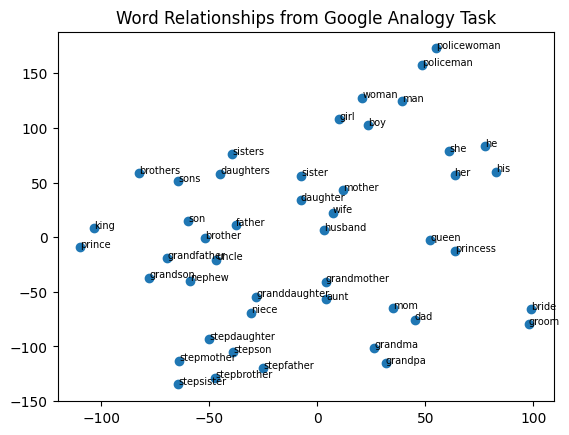

<Figure size 640x480 with 0 Axes>

In [16]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO3: Plot t-SNE for the words in the SUB_CATEGORY `: family`
mask = data["SubCategory"] == SUB_CATEGORY
sub_questions = data[mask]["Question"]

temp_words = []
for i in sub_questions:
    for j in i.split():
        temp_words.append(j)
set_temp_words = set(temp_words)
words = list(set_temp_words)

vectors = np.array([model[i] for i in words])
tsne = TSNE(n_components=2,random_state=42,perplexity=10)
vectors_tsne = tsne.fit_transform(vectors)

for word,(x,y) in zip(words,vectors_tsne):
    plt.annotate(word,(x,y),fontsize=7)
plt.scatter(vectors_tsne[:,0],vectors_tsne[:,1])

plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

### Part III: Train your own word embeddings

### Get the latest English Wikipedia articles and do sampling.
- Usually, we start from Wikipedia dump (https://dumps.wikimedia.org/enwiki/latest/enwiki-latest-pages-articles.xml.bz2). However, the downloading step will take very long. Also, the cleaning step for the Wikipedia corpus ([`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus)) will take much time. Therefore, we provide cleaned files for you.

In [17]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles).
!gdown --id 1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd -O wiki_texts_part_0.txt.gz
!gdown --id 1ABblLRd9HXdXvaNv8H9fFq984bhnowoG -O wiki_texts_part_1.txt.gz
!gdown --id 1z2VFNhpPvCejTP5zyejzKj5YjI_Bn42M -O wiki_texts_part_2.txt.gz
!gdown --id 1VKjded9BxADRhIoCzXy_W8uzVOTWIf0g -O wiki_texts_part_3.txt.gz
!gdown --id 16mBeG26m9LzHXdPe8UrijUIc6sHxhknz -O wiki_texts_part_4.txt.gz

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Failed to retrieve file url:

	Too many users have viewed or downloaded this file recently. Please
	try accessing the file again later. If the file you are trying to
	access is particularly large or is shared with many people, it may
	take up to 24 hours to be able to view or download the file. If you
	still can't access a file after 24 hours, contact your domain
	administrator.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd

but Gdown can't. Please check connections and permissions.
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warn

In [18]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles), except the last file.
!gdown --id 17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI -O wiki_texts_part_5.txt.gz
!gdown --id 19IvB2vOJRGlrYulnTXlZECR8zT5v550P -O wiki_texts_part_6.txt.gz
!gdown --id 1sjwO8A2SDOKruv6-8NEq7pEIuQ50ygVV -O wiki_texts_part_7.txt.gz
!gdown --id 1s7xKWJmyk98Jbq6Fi1scrHy7fr_ellUX -O wiki_texts_part_8.txt.gz
!gdown --id 17eQXcrvY1cfpKelLbP2BhQKrljnFNykr -O wiki_texts_part_9.txt.gz
!gdown --id 1J5TAN6bNBiSgTIYiPwzmABvGhAF58h62 -O wiki_texts_part_10.txt.gz

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Failed to retrieve file url:

	Too many users have viewed or downloaded this file recently. Please
	try accessing the file again later. If the file you are trying to
	access is particularly large or is shared with many people, it may
	take up to 24 hours to be able to view or download the file. If you
	still can't access a file after 24 hours, contact your domain
	administrator.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI

but Gdown can't. Please check connections and permissions.
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warn

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
!unzip drive/MyDrive/wiki/wiki_texts.zip -d /content
!rm -rf /content/__MACOSX

Archive:  drive/MyDrive/wiki/wiki_texts.zip
  inflating: /content/wiki_texts_part_10.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_10.txt.gz  
  inflating: /content/wiki_texts_part_9.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_9.txt.gz  
  inflating: /content/wiki_texts_part_8.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_8.txt.gz  
  inflating: /content/wiki_texts_part_7.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_7.txt.gz  
  inflating: /content/wiki_texts_part_6.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_6.txt.gz  
  inflating: /content/wiki_texts_part_5.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_5.txt.gz  
  inflating: /content/wiki_texts_part_4.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_4.txt.gz  
  inflating: /content/wiki_texts_part_3.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_3.txt.gz  
  inflating: /content/wiki_texts_part_2.txt.gz  
  inflating: /content/__MACOSX/._

In [8]:
# Extract the downloaded wiki_texts_parts files.
!gunzip -k wiki_texts_part_*.gz

In [9]:
# Combine the extracted wiki_texts_parts files.
!cat wiki_texts_part_*.txt > wiki_texts_combined.txt

In [23]:
# Check the first ten lines of the combined file
!head -n 10 wiki_texts_combined.txt

anarchism is political philosophy and movement that is against all forms of authority and seeks to abolish the institutions it claims maintain unnecessary coercion and hierarchy typically including the state and capitalism anarchism advocates for the replacement of the state with stateless societies and voluntary free associations as historically left wing movement this reading of anarchism is placed on the farthest left of the political spectrum usually described as the libertarian wing of the socialist movement libertarian socialism although traces of anarchist ideas are found all throughout history modern anarchism emerged from the enlightenment during the latter half of the th and the first decades of the th century the anarchist movement flourished in most parts of the world and had significant role in workers struggles for emancipation various anarchist schools of thought formed during this period anarchists have taken part in several revolutions most notably in the paris commune

Please note that we used the default parameters of [`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus) for cleaning the Wiki raw file. Thus, words with one character were discarded.

In [24]:
# Now you need to do sampling because the corpus is too big.
# You can further perform analysis with a greater sampling ratio.

import random

wiki_txt_path = "wiki_texts_combined.txt"
output_path = "wiki_texts_20.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # TODO4: Sample `20%` Wikipedia articles
    # Write your code here
        for line in f:
            if random.random() < 0.2:
                output_file.write(line)
print('ok')

ok


In [25]:
# TODO5: Train your own word embeddings with the sampled articles
# https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec
# Hint: You should perform some pre-processing before training.
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from gensim.models.word2vec import LineSentence

sentences = LineSentence("wiki_texts_20.txt")
my_model = Word2Vec(
    sentences = sentences,
    vector_size = 100,
    window = 5,
    min_count = 5,
    workers = 8,
    sg = 0,
    epochs = 5
)
my_model.save("my_model.model")
print("成功")

成功


In [26]:
data = pd.read_csv("questions-words.csv")

In [31]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO6: Write your code here to use your trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      words = analogy.split()
      word_a = words[0]
      word_b = words[1]
      word_c = words[2]
      word_d = words[3]
      golds.append(word_d.lower())
      try:
        guess = my_model.wv.most_similar(positive=[word_b.lower(),word_c.lower()]
                    ,negative=[word_a.lower()]
                    ,topn=1)[0][0]
        preds.append(guess.lower())
      except:
        preds.append("")

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)

for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")


100%|██████████| 19544/19544 [05:55<00:00, 54.98it/s]


Category: Semantic, Accuracy: 64.39282895478632%
Category: Syntactic, Accuracy: 53.039812646370024%
Sub-Category: capital-common-countries, Accuracy: 81.42292490118577%
Sub-Category: capital-world, Accuracy: 77.91777188328912%
Sub-Category: currency, Accuracy: 15.242494226327944%
Sub-Category: city-in-state, Accuracy: 49.00689096068099%
Sub-Category: family, Accuracy: 85.57312252964427%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 20.665322580645164%
Sub-Category: gram2-opposite, Accuracy: 18.472906403940886%
Sub-Category: gram3-comparative, Accuracy: 72.52252252252252%
Sub-Category: gram4-superlative, Accuracy: 40.64171122994652%
Sub-Category: gram5-present-participle, Accuracy: 46.496212121212125%
Sub-Category: gram6-nationality-adjective, Accuracy: 83.42714196372732%
Sub-Category: gram7-past-tense, Accuracy: 51.53846153846153%
Sub-Category: gram8-plural, Accuracy: 59.30930930930931%
Sub-Category: gram9-plural-verbs, Accuracy: 53.5632183908046%


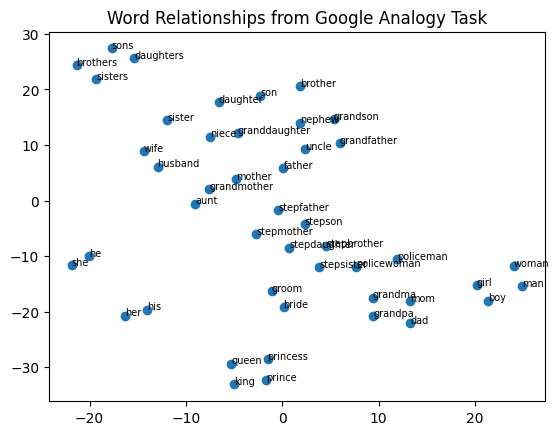

<Figure size 640x480 with 0 Axes>

In [32]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO7: Plot t-SNE for the words in the SUB_CATEGORY `: family`

mask = data["SubCategory"] == SUB_CATEGORY
sub_questions = data[mask]["Question"]

temp_words = []
for i in sub_questions:
    for j in i.split():
        temp_words.append(j)
set_temp_words = set(temp_words)
words = list(set_temp_words)

words = [i for i in words if i in my_model.wv]
vectors = np.array([my_model.wv[i] for i in words])
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
vectors_tsne = tsne.fit_transform(vectors)

plt.scatter(vectors_tsne[:, 0], vectors_tsne[:, 1])
for word, (x, y) in zip(words, vectors_tsne):
    plt.annotate(word, (x, y), fontsize=7)


plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

Running environment:

Python version:

##### 1. Which embedding model do you use? What are the pre-processing steps? What are the hyperparameter settings? (5%)

Answer:
<br>
* 1 使用的是Gensim 的Word2Vec模型，選擇CBOW(sg = 0) 利用周圍上下文詞來預測中心詞<br>
* 2 使用助教提供的 *WikiCorpus* 預先清洗後的維基文本，已經移除了維基百科的 XML 標籤。<br>
使用`random.random()<0.2`對合併的資料抽取20%儲存為`wiki_texts_20.txt`<br>
在訓練前用`LineSentence("wiki_texts_20.txt")`逐行進行空白分詞避免記憶體崩潰<br>
設定詞彙頻率為5的門檻`min_count=5`最終過濾出*1074852*有效詞彙<br>

* 3
  
  * `vector_size = 100`：詞向量維度設為 100，是為了與GloVe (100d) 維持相同的維度基準進行客觀的對比。
  * `window = 5`：目標詞左右各考慮 5 個詞（上下文視野寬度為 10），在捕捉局部句法特徵與廣泛語意關聯間取得良好平衡。
  * `min_count = 5`：忽略出現次數小於 5 的罕見詞，確保留下來的詞彙有足夠的上下文來學好特徵。
  * `sg = 0`：選用CBOW模式節省訓練時間並保證穩定性。
  * `workers = 8`：利用 Colab Pro High-RAM 配置的8核心 CPU 進行多執行緒平行運算加速。
  * `epochs = 5`：在抽樣語料庫上訓練 5 輪。

##### 2. What will the performance be like if you sample 5%, 10% and 20% of wiki text in TODO4? (10%, 3% for each)

Answer:

##### 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

3.1. Present your results. (5%)

Answer:

3.2. Introduce the corpus you selected and explain what are the differences between the Wikipedia corpus and your corpus. (including data size, topic difference, structural difference … ) (5%)

Answer:

3.3. Explain why the performance increases or decreases. (5%)

Answer:

##### 4. Select a few words and use their embeddings to retrieve the five most similar words. What do you observe?  (10%)

Answer:

##### 5. … Anything that can strengthen your report.  (5%)

Answer:

##### 6. Generative AI Usage

Answer:


## Code For 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

In [30]:
# Write your code here

####其他個人程式

In [29]:
from gensim.models import Word2Vec

m = Word2Vec.load("my_model.model")
print("詞典單字數量 (Vocab size):", len(m.wv))

詞典單字數量 (Vocab size): 1074852


In [19]:
#5%

import random

wiki_txt_path = "wiki_texts_combined.txt"
output_path = "wiki_texts_5.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # Sample `5%` Wikipedia articles
    # Write your code here
        for line in f:
            if random.random() < 0.05:
                output_file.write(line)
print('5% ok')

5% ok


In [20]:

#10%
import random

wiki_txt_path = "wiki_texts_combined.txt"
output_path = "wiki_texts_10.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # Sample `10%` Wikipedia articles
    # Write your code here
        for line in f:
            if random.random() < 0.1:
                output_file.write(line)
print('10% ok')

10% ok


In [25]:
import random
from tqdm import tqdm
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from gensim.models.word2vec import LineSentence

# ----------------------------------------------------
# 1. 智慧防呆：確保 data 是 DataFrame 表格
# ----------------------------------------------------
if not isinstance(data, pd.DataFrame):
    try:
        data = pd.read_csv("questions-words.csv")
    except:
        categories, sub_categories, questions = [], [], []
        now_cat, now_sub, count = "", "", 0
        for line in data:
            line = line.strip()
            if not line: continue
            if line.startswith(":"):
                count += 1
                now_sub = line
                now_cat = "Semantic" if count <= 5 else "Syntactic"
            else:
                categories.append(now_cat)
                sub_categories.append(now_sub)
                questions.append(line)
        data = pd.DataFrame({"Question": questions, "Category": categories, "SubCategory": sub_categories})

# 準備標準答案
golds = [q.split()[3].lower() for q in data["Question"]]
golds_np = np.array(golds)

# ----------------------------------------------------
# 2. 訓練並評估 5% 模型
# ----------------------------------------------------
print("=== 步驟 2：訓練 5% 模型 ===")
model_5 = Word2Vec(sentences=LineSentence("wiki_texts_5.txt"), vector_size=100, window=5, min_count=5, workers=8, sg=0, epochs=5)

print("評估 5% 題目中...")
preds_5 = []
for analogy in tqdm(data["Question"]):
    w = analogy.split()
    try:
        preds_5.append(model_5.wv.most_similar(positive=[w[1].lower(), w[2].lower()], negative=[w[0].lower()], topn=1)[0][0].lower())
    except:
        preds_5.append("")
preds_5_np = np.array(preds_5)

# ----------------------------------------------------
# 3. 訓練並評估 10% 模型
# ----------------------------------------------------
print("\n=== 步驟 3：訓練 10% 模型 ===")
model_10 = Word2Vec(sentences=LineSentence("wiki_texts_10.txt"), vector_size=100, window=5, min_count=5, workers=8, sg=0, epochs=5)

print("評估 10% 題目中...")
preds_10 = []
for analogy in tqdm(data["Question"]):
    w = analogy.split()
    try:
        preds_10.append(model_10.wv.most_similar(positive=[w[1].lower(), w[2].lower()], negative=[w[0].lower()], topn=1)[0][0].lower())
    except:
        preds_10.append("")
preds_10_np = np.array(preds_10)

# ----------------------------------------------------
# 4. 20% 既有官方基準數據（來自你的 TODO6 評估結果，無須重跑 20%！）
# ----------------------------------------------------
acc_20_cat = {
    "Semantic": 64.39,
    "Syntactic": 53.04
}
acc_20_sub = {
    ": capital-common-countries": 81.42,
    ": capital-world": 77.92,
    ": currency": 15.24,
    ": city-in-state": 49.01,
    ": family": 85.57,
    ": gram1-adjective-to-adverb": 20.67,
    ": gram2-opposite": 18.47,
    ": gram3-comparative": 72.52,
    ": gram4-superlative": 40.64,
    ": gram5-present-participle": 46.50,
    ": gram6-nationality-adjective": 83.43,
    ": gram7-past-tense": 51.54,
    ": gram8-plural": 59.31,
    ": gram9-plural-verbs": 53.56,
}
ov20 = 58.19

# ----------------------------------------------------
# 5. 🎉 自動印出「5% vs 10% vs 20%」全維度 Markdown 對比表！
# ----------------------------------------------------
print("\n" + "=" * 65)
print("📊 5%、10%、20% 維基語料全維度對比報表（直接複製貼進報告！）：")
print("=" * 65)

print("\n### 【大類別整體對比】")
print("| Category | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 (20% - 5%) |")
print("| :--- | :---: | :---: | :---: | :---: |")
for cat in data["Category"].unique():
    m = data["Category"] == cat
    a5 = np.mean(golds_np[m] == preds_5_np[m]) * 100
    a10 = np.mean(golds_np[m] == preds_10_np[m]) * 100
    a20 = acc_20_cat.get(cat, 0.0)
    print(f"| **{cat}** | {a5:.2f}% | {a10:.2f}% | {a20:.2f}% | +{a20 - a5:.2f}% |")

# Overall
ov5 = np.mean(golds_np == preds_5_np) * 100
ov10 = np.mean(golds_np == preds_10_np) * 100
print(f"| **整體平均 (Overall)** | **{ov5:.2f}%** | **{ov10:.2f}%** | **{ov20:.2f}%** | **+{ov20 - ov5:.2f}%** |")

print("\n### 【14 個子類別精確對比】")
print("| SubCategory | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 |")
print("| :--- | :---: | :---: | :---: | :---: |")
for sub in data["SubCategory"].unique():
    m = data["SubCategory"] == sub
    a5 = np.mean(golds_np[m] == preds_5_np[m]) * 100
    a10 = np.mean(golds_np[m] == preds_10_np[m]) * 100
    a20 = acc_20_sub.get(sub, 0.0)
    print(f"| {sub} | {a5:.2f}% | {a10:.2f}% | {a20:.2f}% | +{a20 - a5:.2f}% |")

=== 步驟 2：訓練 5% 模型 ===
評估 5% 題目中...


100%|██████████| 19544/19544 [02:32<00:00, 128.55it/s]



=== 步驟 3：訓練 10% 模型 ===
評估 10% 題目中...


100%|██████████| 19544/19544 [05:15<00:00, 61.89it/s]


📊 5%、10%、20% 維基語料全維度對比報表（直接複製貼進報告！）：

### 【大類別整體對比】
| Category | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 (20% - 5%) |
| :--- | :---: | :---: | :---: | :---: |
| **Semantic** | 59.17% | 63.37% | 64.39% | +5.22% |
| **Syntactic** | 47.72% | 51.50% | 53.04% | +5.32% |
| **整體平均 (Overall)** | **52.92%** | **56.89%** | **58.19%** | **+5.27%** |

### 【14 個子類別精確對比】
| SubCategory | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 |
| :--- | :---: | :---: | :---: | :---: |
| : capital-common-countries | 83.40% | 80.43% | 81.42% | +-1.98% |
| : capital-world | 73.85% | 76.64% | 77.92% | +4.07% |
| : currency | 6.12% | 9.12% | 15.24% | +9.12% |
| : city-in-state | 40.86% | 50.30% | 49.01% | +8.15% |
| : family | 83.79% | 84.19% | 85.57% | +1.78% |
| : gram1-adjective-to-adverb | 18.04% | 21.57% | 20.67% | +2.63% |
| : gram2-opposite | 11.70% | 14.66% | 18.47% | +6.77% |
| : gram3-comparative | 67.57% | 70.50% | 72.52% | +4.95% |
| : gram4-superlative | 37.34% | 40.11% | 40.64% | +3.30% |